# 03 · Avaliação no teste, erros e limitações

O teste (2025 em diante) não foi usado em nenhuma decisão anterior. Aqui o modelo final, treinado até 2024, é comparado com as
referências ingênuas e os erros são analisados.

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from src import config, features, modelagem

pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False})
config.FIGURAS.mkdir(parents=True, exist_ok=True)
import json
import joblib
from sklearn.inspection import permutation_importance

In [2]:
pacote = joblib.load(config.MODELO)
modelo, X, faixa = pacote["modelo"], pacote["atributos"], pacote["faixa_80"]
dataset = features.preparar(features.carregar())
treino, validacao, teste = features.dividir(dataset)
desenvolvimento = pd.concat([treino, validacao])
print(f"modelo: {pacote['nome']} treinado até {pacote['treinado_ate']} com {len(X)} atributos")
print(f"teste: {teste.index.min():%d/%m/%Y} a {teste.index.max():%d/%m/%Y} ({len(teste)} dias)")

modelo: HistGradientBoosting treinado até 2024-12-31 com 29 atributos
teste: 01/01/2025 a 16/11/2026 (685 dias)


In [3]:
previsto = modelo.predict(teste[X])
prev = {"Persistência (amanhã = hoje)": modelagem.Persistencia().predict(teste[X]),
        "Climatologia (média da época)": modelagem.Climatologia().fit(desenvolvimento[X], desenvolvimento.alvo).predict(teste[X]),
        pacote["nome"]: previsto}
tabela = pd.DataFrame({n: modelagem.metricas(teste.alvo, p) for n, p in prev.items()}).T
dentro = ((teste.alvo >= previsto + faixa[0]) & (teste.alvo <= previsto + faixa[1])).mean()
tabela.to_csv(RAIZ / "reports" / "metricas_teste.csv")
print(f"a máxima real caiu dentro da faixa de 80% em {dentro:.0%} dos dias do teste")
tabela

a máxima real caiu dentro da faixa de 80% em 85% dos dias do teste


,mae,rmse,r2,erro_ate_2c,erro_max
Persistência (amanhã = hoje),2.454,3.219,0.490,0.526,16.200
Climatologia (média da época),2.705,3.360,0.444,0.445,10.473
HistGradientBoosting,1.822,2.325,0.734,0.613,9.243


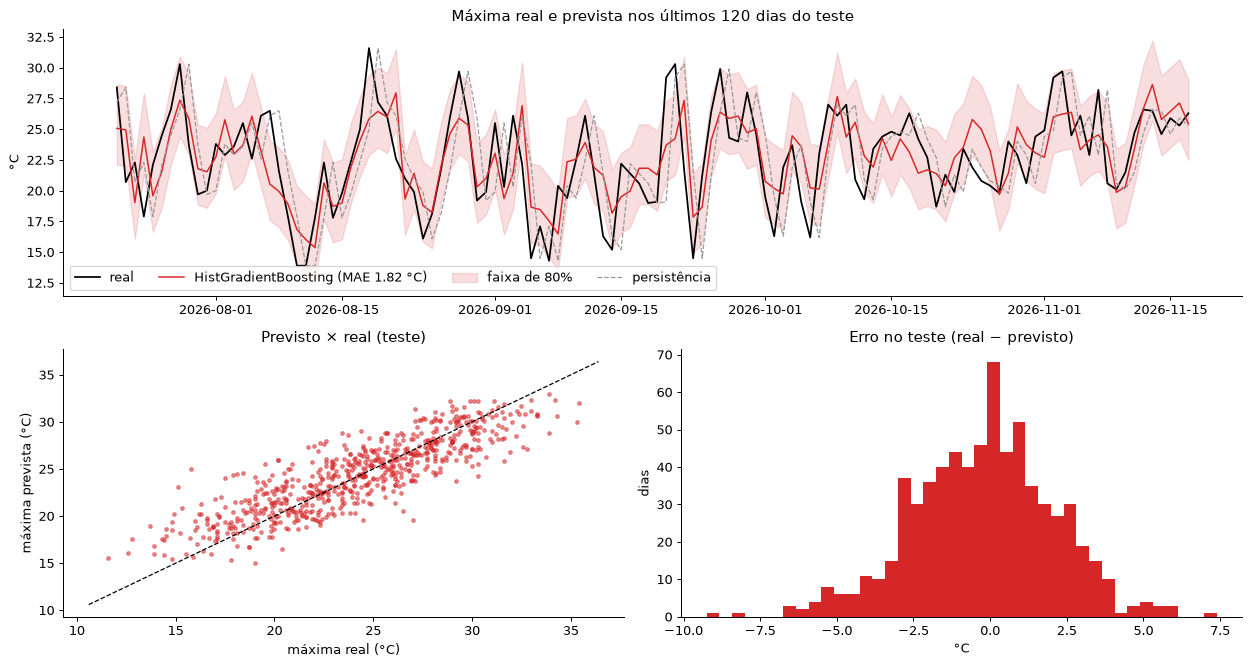

In [4]:
fig = plt.figure(figsize=(14, 7.5))
ax1 = fig.add_subplot(2, 1, 1)
janela = teste.index[-120:]
ax1.plot(janela + pd.Timedelta(days=1), teste.alvo.loc[janela], "k-", lw=1.4, label="real")
ax1.plot(janela + pd.Timedelta(days=1), pd.Series(previsto, teste.index).loc[janela], "-", color="tab:red", lw=1.2,
         label=f"{pacote['nome']} (MAE {tabela.loc[pacote['nome'], 'mae']:.2f} °C)")
ax1.fill_between(janela + pd.Timedelta(days=1), pd.Series(previsto, teste.index).loc[janela] + faixa[0],
                 pd.Series(previsto, teste.index).loc[janela] + faixa[1], color="tab:red", alpha=0.15, label="faixa de 80%")
ax1.plot(janela + pd.Timedelta(days=1), teste.tmax.loc[janela], "--", color="0.6", lw=1, label="persistência")
ax1.set(title="Máxima real e prevista nos últimos 120 dias do teste", ylabel="°C")
ax1.legend(loc="lower left", ncols=4)
ax2 = fig.add_subplot(2, 2, 3)
ax2.scatter(teste.alvo, previsto, s=8, alpha=0.5, color="tab:red")
lim = [teste.alvo.min() - 1, teste.alvo.max() + 1]
ax2.plot(lim, lim, "k--", lw=1)
ax2.set(title="Previsto × real (teste)", xlabel="máxima real (°C)", ylabel="máxima prevista (°C)")
ax3 = fig.add_subplot(2, 2, 4)
(teste.alvo - previsto).clip(-10, 10).plot.hist(bins=40, ax=ax3, color="tab:red")
ax3.set(title="Erro no teste (real − previsto)", xlabel="°C", ylabel="dias")
plt.tight_layout()
plt.savefig(config.FIGURAS / "03_avaliacao.png", bbox_inches="tight")
plt.show()

## Onde o modelo erra?

In [5]:
analise = pd.DataFrame({"real": teste.alvo, "previsto": previsto, "hoje": teste.tmax}, index=teste.index)
analise["erro_abs"] = (analise.real - analise.previsto).abs()
analise["mudanca_real"] = analise.real - analise.hoje
faixas = pd.cut(analise.mudanca_real, [-30, -5, -2, 2, 5, 30],
                labels=["queda > 5 °C", "queda 2–5 °C", "estável (±2 °C)", "alta 2–5 °C", "alta > 5 °C"])
por_mudanca = analise.groupby(faixas, observed=True).agg(dias=("real", "size"), mae_modelo=("erro_abs", "mean"),
                                                         mae_persistencia=("mudanca_real", lambda s: s.abs().mean()))
por_mudanca

,dias,mae_modelo,mae_persistencia
mudanca_real,,,
queda > 5 °C,50,3.536,7.088
queda 2–5 °C,107,2.254,3.340
estável (±2 °C),355,1.364,0.957
alta 2–5 °C,150,1.776,3.239
alta > 5 °C,23,3.464,6.257


Em dias de **tempo estável** os dois erram pouco, e a persistência chega a errar menos: quando nada muda, "amanhã = hoje" é
quase perfeito, enquanto o modelo "puxa" a previsão para o comportamento médio. O ganho do modelo está nas **mudanças**: os
maiores erros aparecem nas mudanças bruscas (passagem de frente fria ou retorno do calor), que dependem de sistemas ainda
longe de Jaraguá do Sul no dia da previsão, mas mesmo nesses dias o modelo erra cerca de **metade** do que erra a persistência,
porque usa sinais como a variação da pressão, as nuvens e a direção do vento.

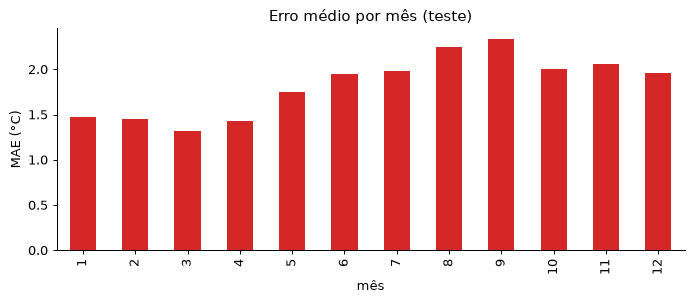

,real,previsto,hoje,erro_abs,mudanca_real
data,,,,,
2025-08-07,15.8,25.0,22.4,9.2,-6.6
2026-06-19,15.1,23.1,20.8,8.0,-5.7
2025-08-21,27.0,19.6,24.8,7.4,2.2
2025-08-13,17.5,24.0,23.5,6.5,-6.0
2026-07-23,17.9,24.4,22.3,6.5,-4.4


In [6]:
mes = analise.groupby(analise.index.month).erro_abs.mean()
ax = mes.plot.bar(figsize=(9, 3.2), color="tab:red")
ax.set(title="Erro médio por mês (teste)", xlabel="mês", ylabel="MAE (°C)")
plt.savefig(config.FIGURAS / "03_erro_mes.png", bbox_inches="tight")
plt.show()
analise.sort_values("erro_abs", ascending=False).head(5).round(1)

## Quais atributos o modelo mais usa?

*Permutation importance* no teste: quanto o MAE piora quando embaralhamos cada atributo (quebrando sua relação com o alvo).

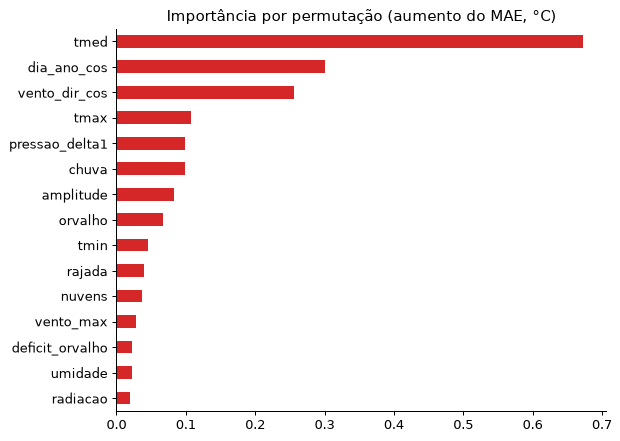

In [7]:
imp = permutation_importance(modelo, teste[X], teste.alvo, scoring="neg_mean_absolute_error", n_repeats=10,
                             random_state=config.SEMENTE, n_jobs=-1)
importancia = pd.Series(imp.importances_mean, index=X).sort_values()
importancia.tail(15).plot.barh(figsize=(7, 5), color="tab:red")
plt.title("Importância por permutação (aumento do MAE, °C)")
plt.tight_layout()
plt.savefig(config.FIGURAS / "03_importancia.png", bbox_inches="tight")
plt.show()

A **temperatura média de hoje** e a **época do ano** dominam, seguidas da **direção do vento** (vento de norte traz ar quente;
de sul, ar frio após as frentes) e da **variação da pressão**, que confirmam o que a exploração mostrou.

## Limitações

- **Dado de reanálise, não de estação:** o ERA5 representa uma célula de ~30 km e suaviza extremos locais. A métrica mede o
  quanto o modelo reproduz o ERA5, não um termômetro no centro da cidade.
- **Só um ponto e só dados diários:** sem informação de cidades vizinhas (de onde vem a frente fria), de altitude ou de
  satélite, que os modelos numéricos de previsão do tempo usam. Por isso o modelo não substitui a previsão oficial.
- **Mudanças bruscas** são o ponto fraco, como mostrado acima.
- **Clima muda:** o modelo deve ser retreinado periodicamente (por exemplo, todo ano) com os dados novos.
- Na demonstração, os dados de hoje vêm da API de previsão (modelos meteorológicos), não do ERA5; as distribuições são
  próximas, mas não idênticas.

In [8]:
(RAIZ / "reports" / "metricas_teste.json").write_text(json.dumps({
    "periodo": [str(teste.index.min().date()), str(teste.index.max().date())], "dias": len(teste),
    "modelo": pacote["nome"], "cobertura_faixa_80": round(float(dentro), 4),
    "metricas": tabela.round(4).to_dict(orient="index"),
    "por_mudanca_de_temperatura": por_mudanca.round(3).reset_index().astype(str).to_dict(orient="records")},
    indent=2, ensure_ascii=False), encoding="utf-8")

1348